**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [ ]:
! pip install lightning torchmetrics torchinfo pyconll transformers

3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*module\(s\) in eval mode at the start of training.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# A grammar exercise with a transformer

In this notebook, we will again work on the [noun verb](https://github.com/google-research-datasets/noun-verb) dataset.
This dataset contains natural English sentences where there can be some ambiguity about the role of a word, i.e., whether it is a noun or a verb.

Below are a few observations from this dataset illustrating the task. The word in bold is the word to classify, and the word in italics after the sentence indicates the correct answer:

> Certain insects can damage plumerias, such as mites, **flies**, or aphids. *NOUN*

> **Mark** which area you want to distress. *VERB*

For example, the word **flies** can correspond to the third person singular of the verb *fly* (e.g., *time flies by so fast*), but also to the plural of the noun *fly*.
Similarly, the word **mark** can correspond to the verb *mark* or the noun *mark*.

The task is therefore a binary classification since there are only two possible classes: *noun* or *verb*.

## Loading and preprocessing the data

We will apply the same data preprocessing steps as in the other notebook, i.e., transform each token into a $50$-dimensional numerical vector using GloVe *embeddings*.

In [3]:
! mkdir -p data && cd data && (test -f glove.6B.zip || wget https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip) && unzip -o -q glove.6B.zip

--2026-11-01 20:28:44--  https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
Resolving huggingface.co (huggingface.co)... 2600:9000:2111:6a00:17:b174:6d00:93a1, 2600:9000:2111:5400:17:b174:6d00:93a1, 2600:9000:2111:4200:17:b174:6d00:93a1, ...
Connecting to huggingface.co (huggingface.co)|2600:9000:2111:6a00:17:b174:6d00:93a1|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.aws.cdn.hf.co/xet-bridge-us/621ffdc136468d709f18095d/ded22944ac944002f423d1cdb83de044851330e1a7fe19d74dc59ffa632ad294?response-content-type=application%2Fzip&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27glove.6B.zip%3B+filename%3D%22glove.6B.zip%22%3B&user_id=public&xip=5UO3i6k9Uvs&X-Xet-Cas-Uid=public&Expires=1793564925&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5hd3MuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTgwOTVkL2RlZDIyOTQ0YWM5NDQwMDJmNDIzZDFjZGI4M2RlMDQ0ODUxMzMwZTFhN2ZlMTlkNzRkYzU5ZmZhNjMyYWQyOTRcXD9yZXNwb25zZ

In [4]:
import numpy as np
import torch


def load_dataset(path="data"):
    """Load the noun verb dataset.

    Parameters
    ----------
    path : str
        Path to the directory.

    Returns
    -------
    train : Conll
        Training set.

    validation : Conll
        Validation set.

    test : Conll
        Test set.
    """
    import os
    import pyconll
    from urllib.request import urlretrieve

    if not os.path.exists(path):
        os.makedirs(path)

    files = ("train.conll", "dev.conll", "test.conll")

    # Downloads the files if necessary
    for file in files:
        if not os.path.isfile(os.path.join(path, file)):
            url = f"https://raw.githubusercontent.com/google-research-datasets/noun-verb/master/{file}"
            urlretrieve(url, os.path.join(path, file))

    return (pyconll.load_from_file(os.path.join(path, file)) for file in files)


def load_embeddings(path="data"):
    """Load the GloVe 50d embeddings.

    Parameters
    ----------
    path : str
        Path to the directory

    Returns
    -------
    embeddings : dict
        GloVe 50d embeddings.
    """
    import os

    # Save the results in a dictionary
    embeddings = {}

    # Get the embedding for each token in the file
    mean = torch.zeros(50, dtype=torch.float32)
    with open(os.path.join(path, "glove.6B.50d.txt"), "r") as file:
        for line in file.readlines():
            split = line.strip().split(" ")
            token = split[0]
            value = torch.from_numpy(np.array(split[1:], dtype=np.float32))
            embeddings[token] = value
            mean += value

    # Define the mean embedding for out-of-vocabulary token
    embeddings["out_of_vocabulary"] = mean / len(embeddings)

    return embeddings


def preprocess_dataset(dataset, embeddings):
    """Preprocess a data set.

    Parameters
    ----------
    dataset : Conll
        Data set.

    embeddings : dict
        Embedding of each token.

    Returns
    -------
    x : list[Tensors]
        Preprocessed inputs.

    y : Tensor
        Preprocessed outputs.

    index : Tensor
        Indices of the tokens of interest.
        
    mapping : list
        Indices of the samples.
    """

    x = []
    y = []
    index = []
    mapping = []

    label_mapping = {"NON-VERB": 0, "VERB": 1}

    for count, sentence in enumerate(dataset):

        embedded_sentence = []
        label = None
        idx = None

        for i, token in enumerate(sentence):

            # Get the token in lowercase
            token_lower = token.form.lower()

            # Get the embedding of the token
            if token_lower in embeddings.keys():
                embedded_sentence.append(embeddings[token_lower].reshape(1, -1))
            else:
                embedded_sentence.append(embeddings["out_of_vocabulary"].reshape(1, -1))

            # Get the label (if any)
            if len(token.feats):
                if label is not None:
                    raise ValueError("Two annotated tokens in a single sentence.")
                label = label_mapping[next(iter(token.feats["POS"]))]
                idx = i

        # Add the preprocessed sample to the dataset only if there is a label available
        if label is not None:
            x.append(torch.concat(embedded_sentence))
            y.append(label)
            index.append(idx)
            mapping.append(count)

    y = torch.tensor(y).to(dtype=torch.float32)
    index = torch.tensor(index).to(dtype=torch.int64)

    return x, y, index, mapping

In [5]:
# Load the dataset
training, validation, test = load_dataset()

# Load the embeddings
embeddings = load_embeddings()

# Preprocess the dataset
x_train, y_train, index_train, mapping_train = preprocess_dataset(training, embeddings)
x_val, y_val, index_val, mapping_val = preprocess_dataset(validation, embeddings)
x_test, y_test, index_test, mapping_test = preprocess_dataset(test, embeddings)

## Reminder

In a previous practical session, we used a bidirectional recurrent neural network.
The image below summarizes the architecture we implemented:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/brnn_specific_token.png" width="450"/>](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/brnn_specific_token.png)

This approach has several limitations:

* In the forward direction, only the tokens located before the token of interest are taken into account. Similarly, in the backward direction, only the tokens located after the token of interest are taken into account. By concatenating the two hidden states, all tokens are taken into account, but this only happens later in the architecture.

* The hidden state of the token of interest must contain all the relevant information contained in all the preceding tokens, which can be difficult for long sentences.


## Attention mechanism

The main idea of the attention mechanism is as follows: instead of taking into account a single hidden state obtained by a recurrent neural network, we can take into account all the inputs using a **convex combination** of the inputs.
Thus, a hidden vector no longer needs to contain all the relevant information, since we will have a dedicated layer to retrieve the relevant information from the corresponding inputs through *attention weights*.

An attention function can be described as a mapping between a *query* and a set of (*key*, *value*) pairs to produce an output.
The query, each key, each value, and the output are all numerical vectors.
This output is computed as a weighted sum of the values, where the weights are computed based on the similarity between the query and the keys.

There are several mathematical functions to compute this.
Here, the function considered is scaled dot-product attention:
$$
    \text{Attention}(Q, K, V) = \text{softmax}\left( \frac{Q K^\top}{\sqrt{d_k}} \right) V
$$
where $Q$, $K$, and $V$ are the matrices corresponding to the queries, keys, and values respectively, and where $d_k$ is the dimension of the query and key vectors.
The scaling is done to prevent the scale of the dot products from depending too heavily on the dimension $d_k$.


### Multi-head attention

The main idea of multi-head attention is simply to perform several attention functions instead of a single one, but without increasing the total dimension.
To do this, each attention function is performed in smaller dimensions by linearly projecting the queries, keys, and values into different lower-dimensional spaces:
$$
    \text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, \ldots, \text{head}_h) W^O \\
    \text{where } \text{head}_i = \text{Attention}(Q W_i^Q, K W_i^K, V W_i^V) 
$$

The image below illustrates scaled dot-product attention (left) and multi-head attention (right):

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/attention.png" width="650"/>](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/attention.png)

## Implementation in `PyTorch`

Multi-head attention is implemented in the [`torch.nn.MultiheadAttention()`](https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html) class.
The required arguments of this class are:
* `embed_dim`: dimension of the vectors (queries, keys, and values),
* `num_heads`: number of attention heads.
Please note that the total dimension `embed_dim` is split among the heads, i.e., each head has dimension `embed_dim / num_heads`.

To apply the forward pass of this layer, at least three required arguments must be provided as input: `query` (the queries), `key` (the keys), and `value` (the values).
An optional argument, `key_padding_mask`, indicates which elements among the keys to ignore in the attention computation.
More information on this in the next section.


### Padding

With sequential data, we often find ourselves working with variable-length tensors.
As with recurrent neural networks, we use padding, i.e., possibly adding zeros at the end of tensors, so that all potentially padded observations in the batch have the same length.
However, it is necessary to indicate which values were padded so that the attention function does not use them.
This is exactly what the `key_padding_mask` argument allows us to do.
One possible representation is a binary mask where the values `True` indicate elements to ignore.
The code below illustrates how to pad a list of sequences and how to compute the padding mask.

```python
import torch
from torch.nn.utils.rnn import pad_sequence

sequence1 = torch.rand(6, 50)  # a sequence of length 6
sequence2 = torch.rand(10, 50)  # a sequence of length 10
sequence3 = torch.rand(9, 50)  # a sequence of length 9

sequences = [sequence1, sequence2, sequence3]

# We compute the length of each sequence
lens = [sequence.size()[0] for sequence in sequences]
max_len = max(lens)

# We generate the padding mask for the attention layer.
key_padding_mask = torch.vstack([
    torch.cat((torch.full((length,), False), torch.full((max_len - length,), True)))
    for length in lens
])

# We pad the list of sequences
sequences_padded = pad_sequence(sequences)
```

### Question 1

We will build a neural network with the following architecture:

* First layer: multi-head attention with a single head.
* Second layer: linear layer with 50 input variables and 32 output variables + ReLU activation function.
* Third layer: linear layer with 1 output variable.

For the attention layer, you will use [`torch.nn.MultiheadAttention()`](https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html).
Take the time to read the documentation of this class.

A few important notes:

* The `forward()` method of [`torch.nn.MultiheadAttention()`](https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html) has an argument called `need_weights` whose default value is `True`. The documentation suggests setting this value to `False` to use a more optimized version and get the best performance. Although our model does not use the attention weights, we will leave this argument set to `True` in order to visualize the weights obtained. **In particular, the `forward()` method of the `AttentionNetwork()` class must return the attention weights**.
* The attention layer will return the attention outputs and attention weights for all tokens. We are only interested in the output and weights for the token of interest (corresponding to the word to label).

Complete the missing code in the `__init__()` and `forward()` methods of the `AttentionNetwork()` class.

In [6]:
import lightning as L
from torch.nn.utils.rnn import pad_sequence
from torchmetrics import Accuracy


class AttentionNetwork(L.LightningModule):
    def __init__(self, num_heads=1):
        super().__init__()
        
        ### BEGIN TODO ###
        # Instantiate the elements of the architecture
        self.attention = torch.nn.MultiheadAttention(embed_dim=50, num_heads=num_heads)
        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(50, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1)
        )
        #### END TODO ####
        
        self.loss = torch.nn.BCEWithLogitsLoss()

        self.accuracy_train = Accuracy(task="binary")
        self.accuracy_val = Accuracy(task="binary")
        self.accuracy_test = Accuracy(task="binary")

    def forward(self, x, index):
        """Implements the forward pass.
        
        Parameters
        ----------
        x : list[Tensor], len = batch_size
            Batch of sequences of vectors.
        
        index : tensor, shape = (batch_size,)
            Index of the token of interest in each sequence.

        Returns
        -------
        logits : Tensor, shape = (batch_size,)
            Logits.
        
        attn_weights : list[Tensor], len = batch_size
            List of the attention weights for each token of interest.
        """
        ### BEGIN TODO ###
        # Compute the length of each sequence and the maximal length in this batch
        lens = [sequence.size()[0] for sequence in x]
        max_len = max(lens)

        # Generate the padding mask
        key_padding_mask = torch.vstack([
            torch.concat((torch.full((length,), False), torch.full((max_len - length,), True)))
            for length in lens
        ]).to(self.device)
        
        # Pad the smallest sequences
        x_padded = pad_sequence(x)
        
        # Get the queries for the tokens of interest only
        x_query = torch.unsqueeze(
            torch.stack([x_padded[idx, i] for i, idx in enumerate(index)]), dim=0
        )

        # Compute the attention outputs and the attention weights
        h, attn_output_weights = self.attention(
            x_query, x_padded, x_padded, key_padding_mask=key_padding_mask
        )
        h = torch.squeeze(h, dim=0)
        
        # Remove padding in the attention weights
        attn_weights = [
            attn_output_weights[i, 0, :length] for i, length in enumerate(lens)
        ]
        
        # Feed the attention outputs to the multilayer perceptron to obtain the logits
        logits = torch.squeeze(self.mlp(h), dim=1)
        #### END TODO ####

        return logits, attn_weights
    
    def step(self, batch, dataset):
        """Perform a step.
        
        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.
            
        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        # Get the inputs, outputs, and indices for this batch
        x = [item[0].to(self.device) for item in batch]
        y = torch.tensor([item[1] for item in batch], device=self.device)
        index = torch.tensor([item[2] for item in batch], device=self.device)

        logits, _ = self(x, index)  # Forward pass outputting the logits (and the attention weights)
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = (logits > 0).to(torch.float32)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        elif dataset == "validation":
            metric = self.accuracy_val
            name = "val"
            bar_step = False
        else:
            metric = self.accuracy_test
            name = "test"
            bar_step = False
        
        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def test_step(self, batch):
        """Perform a test step."""
        return self.step(batch, "test")
    
    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

### Datasets and dataloaders

Since the code related to the datasets and dataloaders remains unchanged from the previous notebook, it is provided below:

In [7]:
from torch.utils.data import Dataset, DataLoader


class CustomDataset(Dataset):
    def __init__(self, x, y, index):
        self.x = x
        self.y = y
        self.index = index

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx], self.index[idx]

    
batch_size = 64

dataloader_train = DataLoader(
    CustomDataset(x_train, y_train, index_train),
    batch_size=batch_size, shuffle=True, collate_fn=lambda x: x
)

dataloader_val = DataLoader(
    CustomDataset(x_val, y_val, index_val),
    batch_size=batch_size, shuffle=False, collate_fn=lambda x: x
)

dataloader_test = DataLoader(
    CustomDataset(x_test, y_test, index_test),
    batch_size=batch_size, shuffle=False, collate_fn=lambda x: x
)

### Training

We will train our model for 10 epochs.

In [8]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_attention = AttentionNetwork()

trainer_attention = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    callbacks=[TQDMProgressBar(refresh_rate=10)]
)

trainer_attention.fit(
    model=model_attention,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 0



Validation: |                                                                                                 …

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.61026    | 66.2064% |
| Validation |    0.60277    | 68.4833% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.57781    | 69.4871% |
| Validation |    0.59215    | 68.6101% |
----------------------------------------- 



... (12 outputs left out)

Validation: |                                                                                                 …

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.51294    | 75.1094% |
| Validation |    0.58780    | 70.2577% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.50689    | 75.5768% |
| Validation |    0.59182    | 69.8775% |
----------------------------------------- 



## Visualization

Now that we have trained our model with an attention layer, we can visualize the attention weights given to the different tokens of a sentence to see which words are considered important for classification.

The `plot_attention_weights()` function defined below displays the attention weights for a given sentence.

In [9]:
import matplotlib.pyplot as plt


def plot_attention_weights(model, dataset, idx, **kwargs):
    """Plots a sample and the attention weights learned by the trained model.
    
    Parameters
    ----------
    model : LightningModule
        Trained model.
    
    dataset : {"train", "validation", "test"}
        Data set.
    
    idx : int
        Index of the sample in the data set.
        
    kwargs : optional
        Other optional keyword arguments provided to the `forward()` method of the trained model.
    """
    
    if dataset == "train":
        dataset = training
        x = x_train
        y = y_train
        index = index_train
        mapping = mapping_train
    elif dataset == "validation":
        dataset = validation
        x = x_val
        y = y_val
        index = index_val
        mapping = mapping_val
    elif dataset == "test":
        dataset = test
        x = x_test
        y = y_test
        index = index_test
        mapping = mapping_test
        
    # Check if the index is valid
    if not (0 <= idx < len(y)):
        raise ValueError(
            f"The provided index is invalid for this dataset. "
            f"The size of this data set is {len(y)}."
        )
    
    # Get original labels
    label_inverse_mapping = {False: "NOUN", True: "VERB"}
    
    # Compute prediction and attention weights
    model.eval()
    with torch.no_grad():
        pred, attn = model(
            [x_.to(model.device) for x_ in x[idx:idx+1]], index[idx:idx+1].to(model.device), **kwargs
        )
    y_pred = label_inverse_mapping[pred.item() > 0]

    # Plot the results
    plt.figure(figsize=(14, 2))
    plt.imshow(attn[0].cpu().numpy().reshape(1, -1), cmap="seismic", vmin=0., vmax=1.)
    plt.xticks(-0.5 + np.arange(0, len(x[idx])), [])
    plt.yticks([])
    plt.tick_params(length=0)

    for i, token in enumerate(dataset[mapping[idx]]):
        if i == index[idx:idx+1]:
            color = "C0"
            fontweight = "bold"
        else:
            color = "k"
            fontweight = "normal"
        plt.text(i, -0.6, token.form, color=color, rotation=45, fontweight=fontweight, ha="left")

    plt.grid(which="major", color="C2", linestyle="--", linewidth=2)

    colorbar = plt.colorbar(orientation="horizontal")
    colorbar.set_ticks(np.linspace(0, 1, 6))
    colorbar.set_ticklabels([f"{tick: >.1f}" for tick in np.linspace(0, 1, 6)])
    
    print(f"True label = {label_inverse_mapping[y[idx].item() == 1]}")
    print(f"Predicted label = {label_inverse_mapping[pred.item() > 0]}")

### Question 2

Use the `plot_attention_weights()` function to display the attention weights of each token for a few sentences from the training, validation, and test sets.

True label = NOUN
Predicted label = VERB


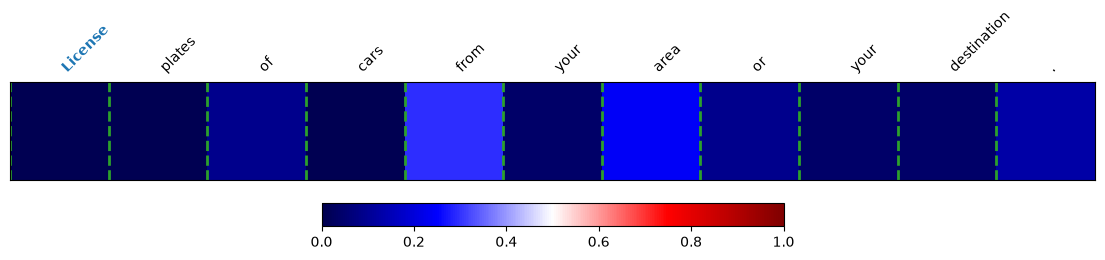

In [10]:
plot_attention_weights(model_attention, "train", 0)

True label = VERB
Predicted label = VERB


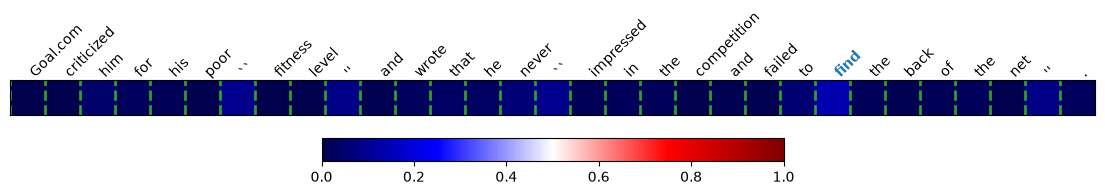

In [11]:
plot_attention_weights(model_attention, "train", 2023)

True label = VERB
Predicted label = VERB


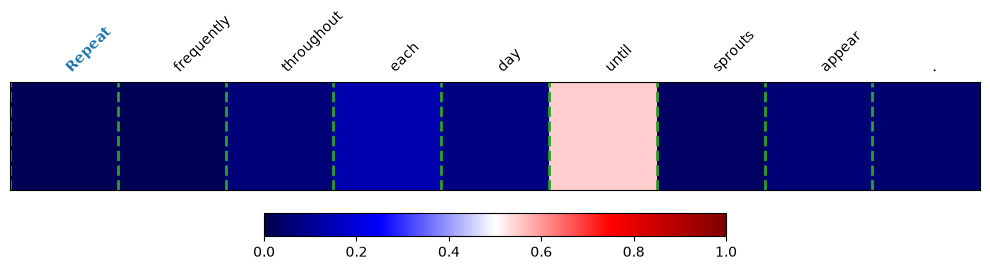

In [12]:
plot_attention_weights(model_attention, "validation", 20)

True label = NOUN
Predicted label = NOUN


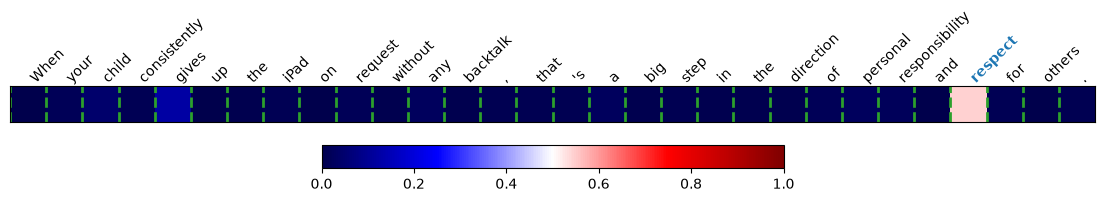

In [13]:
plot_attention_weights(model_attention, "validation", 23)

True label = VERB
Predicted label = VERB


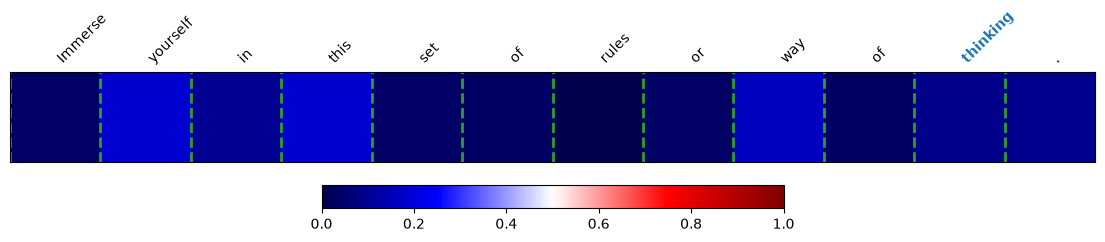

In [14]:
plot_attention_weights(model_attention, "test", 22)

True label = VERB
Predicted label = VERB


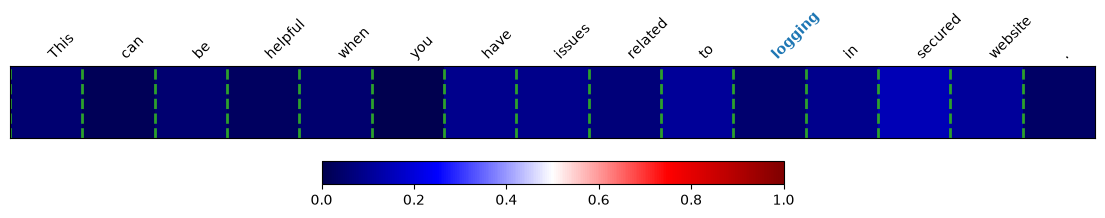

In [15]:
plot_attention_weights(model_attention, "test", 43)

You may have noticed that the model's performance is not exceptional, with an accuracy score, i.e., the proportion of correct answers, of about $70\%$.
As a reminder, with a trivial model predicting only verbs, we would obtain the following performance:

In [16]:
print(f"Proportion of verbs in the training set = {y_train.mean().item():.2%}")
print(f"Proportion of verbs in the validation set = {y_val.mean().item():.2%}")
print(f"Proportion of verbs in the test set = {y_test.mean().item():.2%}")

Proportion of verbs in the training set = 63.57%
Proportion of verbs in the validation set = 66.37%
Proportion of verbs in the test set = 65.82%


The attention module is an essential element of a transformer's architecture, but this architecture is much more complex and does not use only a single attention module.

## Transformer

The image below illustrates the architecture of a transformer:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/transformer.png" width="450"/>](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/transformer.png)

This architecture is composed of two parts:

* The encoder (left) consists of a stack of $N$ ($N = 6$ in the original architecture) encoding layers, all with the same architecture. Each encoding layer is composed of two sublayers. The first sublayer corresponds to multi-head attention, while the second sublayer is a simple multilayer perceptron (2 linear layers with the ReLU activation function in between).

* The decoder (right) consists of a stack of $N$ ($N = 6$ in the original architecture) decoding layers, all with the same architecture. Each decoding layer is composed of three sublayers: masked multi-head self-attention, multi-head attention over the output of the encoder, and a multilayer perceptron.


### Implementation in `PyTorch`

`PyTorch` provides several classes for the [different layers of a transformer](https://pytorch.org/docs/stable/nn.html#transformer-layers):

* [`torch.nn.Transformer()`](https://pytorch.org/docs/stable/generated/torch.nn.Transformer.html): a full transformer.
* [`torch.nn.TransformerEncoder()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html): a transformer encoder (i.e., a stack of several transformer encoding layers).
* [`torch.nn.TransformerDecoder()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerDecoder.html): a transformer decoder (i.e., a stack of several transformer decoding layers).
* [`torch.nn.TransformerEncoderLayer()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html): a transformer encoding layer.
* [`torch.nn.TransformerDecoderLayer()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerDecoderLayer.html): a transformer decoding layer.


### Question 3

We will build a model whose architecture is based on that of the transformer.
The encoder is used to learn a code for the input.
The decoder of a transformer is used to generate the output sequence from the input code (for example, the translation of a sentence).
Here, we do not need to generate an output sequence, so we do not need the decoder.

The transformer encoder returns a code for the input sequence, i.e., a code for each of the tokens in the sentence.
We are only interested in the code of the token of interest (the word to label), so we will only keep this code in the output.

The architecture of our model will be as follows:
* *Positional encoding* (provided): the attention mechanism does not take into account the order of the tokens, so a vector depending on the position of each token is added to its embedding (see the `PositionalEncoding()` class);
* *First layer*: transformer encoder;
* *Second layer*: linear layer with $50$ input variables and $1$ output variable.

Complete the missing code in the `__init__()` method of the `TransformerNetwork()` class.

In [17]:
import math


class PositionalEncoding(torch.nn.Module):
    """Sinusoidal positional encoding.

    The attention mechanism does not take into account the order of the tokens.
    The positional encoding adds to the embedding of each token a vector that
    depends on the position of the token in the sequence.

    Parameters
    ----------
    d_model : int
        Dimension of the embeddings.

    max_len : int (default = 1000)
        Maximum length of the sequences.
    """
    def __init__(self, d_model, max_len=1000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe)

    def forward(self, x):
        """Add the positional encoding.

        Parameters
        ----------
        x : Tensor, shape = (seq_len, batch_size, d_model)
            Padded sequences of embeddings.

        Returns
        -------
        x_new : Tensor, shape = (seq_len, batch_size, d_model)
            Padded sequences of embeddings with the positional encoding.
        """
        return x + self.pe[:x.size(0)]


class TransformerNetwork(L.LightningModule):
    """Our network.

    Parameters
    ----------
    num_layers : int (default = 6)
        Number of encoding layers.

    nhead : int (default = 5)
        Number of heads in the multihead attention layer.

    dropout_encoder_layer : float (default = 0.0)
        Dropout rate used in each encoding layer.
    """
    def __init__(self, num_layers=6, nhead=5, dropout_encoder_layer=0.0):
        super().__init__()

        # Positional encoding (provided)
        self.positional_encoding = PositionalEncoding(d_model=50)

        ### BEGIN TODO ###
        self.transformer_encoder = torch.nn.TransformerEncoder(
            torch.nn.TransformerEncoderLayer(
                d_model=50, nhead=nhead, dropout=dropout_encoder_layer
            ),
            num_layers=num_layers, enable_nested_tensor=False
        )
        self.linear = torch.nn.Linear(50, 1)
        #### END TODO ####

        self.loss = torch.nn.BCEWithLogitsLoss()
        self.accuracy_train = Accuracy(task="binary")
        self.accuracy_val = Accuracy(task="binary")
        self.accuracy_test = Accuracy(task="binary")

    def forward(self, x, index, compute_attn_weights=False):
        """Forward method.

        Parameters
        ----------
        x : list[Tensor], len = batch_size
            Sequence of embeddings.

        index : tensor, shape = (batch_size,)
            Index of the token of interest in each sequence.

        compute_attn_weights : bool (default = False)
            If True, the attention weights of the first block of the
            transformer encoder are computed and returned.

        Returns
        -------
        logits : Tensor, shape = (batch_size,)
            Logits.

        attn_weights : Tensor
            Attention weights. Only returned if `compute_attn_weights` is True.
        """
        # Compute the length of each sequence and the maximal length in this batch
        lens = [sequence.size()[0] for sequence in x]
        max_len = max(lens)

        # Generate the padding mask
        key_padding_mask = torch.vstack([
            torch.concat((torch.full((length,), False), torch.full((max_len - length,), True)))
            for length in lens
        ]).to(self.device)

        # Pad the smallest sequences
        x_padded = pad_sequence(x)

        # Add the positional encoding
        x_padded = self.positional_encoding(x_padded)

        # Transformer encoder
        transformer_encoder_output = self.transformer_encoder(
            x_padded, src_key_padding_mask=key_padding_mask
        )

        # Get the attention outputs for the tokens of interest only
        h = torch.vstack([transformer_encoder_output[idx, i] for i, idx in enumerate(index)])

        # Apply the linear layer
        logits = torch.squeeze(self.linear(h), dim=1)

        if not compute_attn_weights:
            return logits

        else:
            # Compute the attention weights of the first block of the transformer encoder
            _, attn_output_weights = self.transformer_encoder.layers[0].self_attn(
                x_padded, x_padded, x_padded, key_padding_mask=key_padding_mask
            )

            # Get the attention weights for the tokens of interest only
            attn_weights = [
                attn_output_weights[i, idx, :length] for i, (idx, length) in enumerate(zip(index, lens))
            ]

            return logits, attn_weights

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        # Get the inputs, outputs, and indices for this batch
        x = [item[0].to(self.device) for item in batch]
        y = torch.tensor([item[1] for item in batch], device=self.device)
        index = torch.tensor([item[2] for item in batch], device=self.device)

        logits = self(x, index)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = (logits > 0).to(torch.float32)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        elif dataset == "validation":
            metric = self.accuracy_val
            name = "val"
            bar_step = False
        else:
            metric = self.accuracy_test
            name = "test"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def test_step(self, batch):
        """Perform a test step."""
        return self.step(batch, "test")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

### Question 4

Train a new model with the architecture defined above, with $2$ encoding layers and $1$ head, for $10$ epochs.

In [18]:
### BEGIN TODO ###
model_transformer = TransformerNetwork(num_layers=2, nhead=1)
#### END TODO ####

trainer_transformer = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    callbacks=[TQDMProgressBar(refresh_rate=10)]
)

trainer_transformer.fit(
    model=model_transformer,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 1



Validation: |                                                                                                 …

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.56569    | 70.1904% |
| Validation |    0.55700    | 71.5674% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.48563    | 76.1858% |
| Validation |    0.53350    | 73.8065% |
----------------------------------------- 



... (12 outputs left out)

Validation: |                                                                                                 …

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.26188    | 89.1200% |
| Validation |    0.58734    | 76.0456% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.24159    | 89.9391% |
| Validation |    0.62704    | 75.4542% |
----------------------------------------- 



### Question 5

Visualize the weights of the first attention layer generated by this new model using the `plot_attention_weights()` function for a few sentences from the training, validation, and test sets.

True label = NOUN
Predicted label = VERB


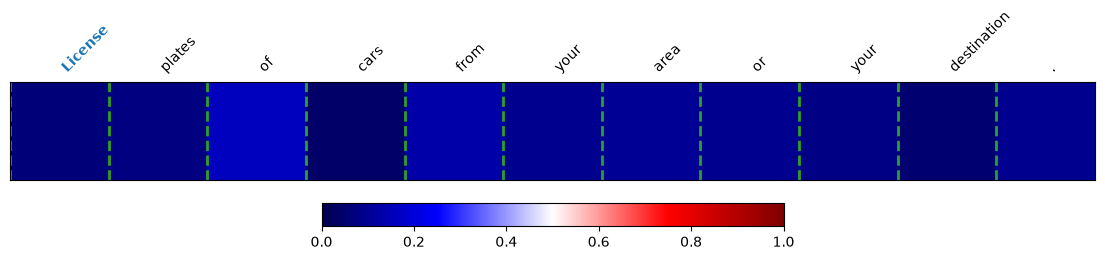

In [19]:
plot_attention_weights(model_transformer, "train", 0, compute_attn_weights=True)

True label = VERB
Predicted label = VERB


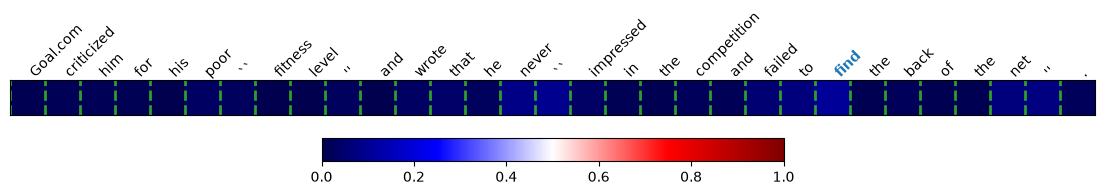

In [20]:
plot_attention_weights(model_transformer, "train", 2023, compute_attn_weights=True)

True label = VERB
Predicted label = VERB


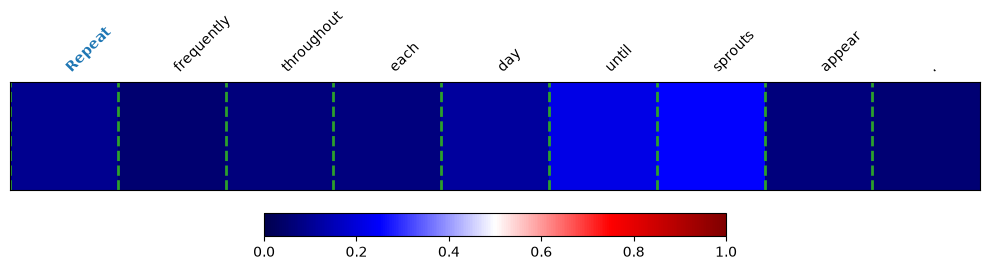

In [21]:
plot_attention_weights(model_transformer, "validation", 20, compute_attn_weights=True)

True label = NOUN
Predicted label = NOUN


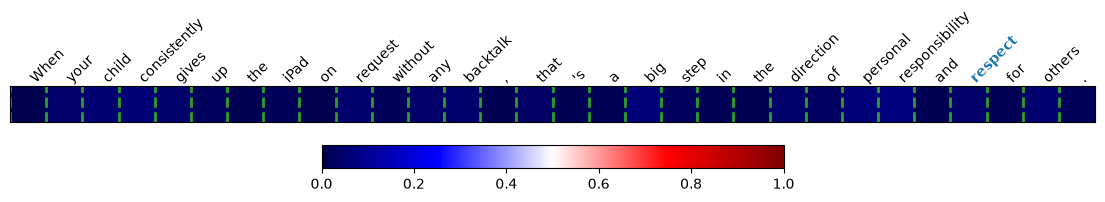

In [22]:
plot_attention_weights(model_transformer, "validation", 23, compute_attn_weights=True)

True label = VERB
Predicted label = VERB


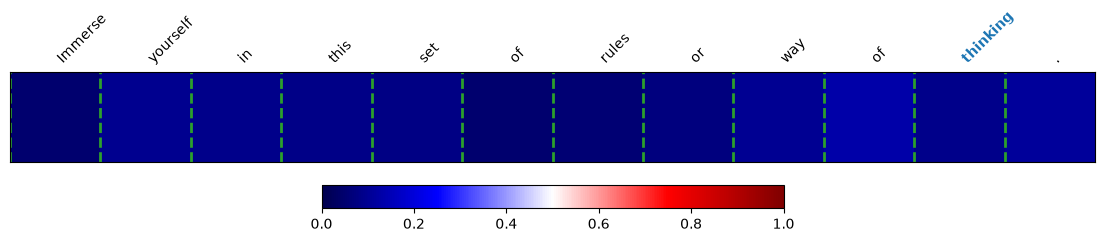

In [23]:
plot_attention_weights(model_transformer, "test", 22, compute_attn_weights=True)

True label = VERB
Predicted label = VERB


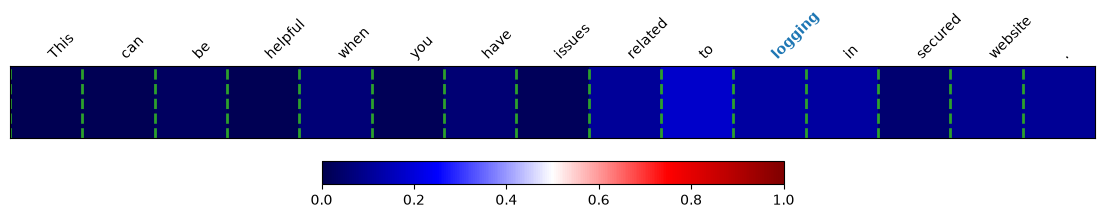

In [24]:
plot_attention_weights(model_transformer, "test", 43, compute_attn_weights=True)

## Using a pretrained transformer

Our transformer is trained from scratch on about $23{,}000$ sentences, and its only knowledge about the words comes from the GloVe embeddings, which do not depend on the context.
In practice, transformers are rarely trained from scratch on such small datasets.
Instead, we use a model **pretrained** on a very large amount of text, and we adapt it to our task.

### BERT

[BERT](https://arxiv.org/abs/1810.04805) (*Bidirectional Encoder Representations from Transformers*) is a transformer encoder pretrained on a large corpus of English text (books and Wikipedia).
Its main pretraining task is *masked language modeling*: some tokens of a sentence are hidden, and the model must predict them using the other tokens of the sentence.
To solve this task, the model must learn the meaning of the words **in their context**, which is exactly what we need to know if a word is a noun or a verb.

The original BERT model is quite large (110 million parameters), but [smaller versions](https://github.com/google-research/bert) have also been released.
We will use **BERT-mini** ([`google/bert_uncased_L-4_H-256_A-4`](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4)): $4$ encoding layers, a dimension of $256$, $4$ heads, and about $11$ million parameters.

A few differences with our transformer:

* **Tokens**: BERT does not use words as tokens, but **sub-words** (*WordPiece* tokenization). Frequent words are a single token, while rare words are split into several sub-words (the sub-words that do not start a word are prefixed with `##`). This way, there are no out-of-vocabulary words. Two special tokens are also added: `[CLS]` at the beginning and `[SEP]` at the end of each sentence.
* **Positional encoding**: BERT uses **learned** positional embeddings (one vector per position, learned during pretraining) instead of sinusoidal positional encodings.
* **Shape of the tensors**: the tensors are of shape `(batch_size, seq_len, hidden_size)` (*batch first*).

We will use the [`transformers`](https://huggingface.co/docs/transformers) library to load the pretrained tokenizer and model.

### Tokenization

In [25]:
from transformers import AutoTokenizer

CHECKPOINT = "google/bert_uncased_L-4_H-256_A-4"
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)


def get_words(dataset, mapping):
    """Get the tokens of each sentence as a list of strings.

    Parameters
    ----------
    dataset : Conll
        Data set.

    mapping : list
        Indices of the samples.

    Returns
    -------
    words : list[list[str]]
        Tokens of each sentence.
    """
    return [[token.form for token in dataset[i]] for i in mapping]


words_train = get_words(training, mapping_train)
words_val = get_words(validation, mapping_val)
words_test = get_words(test, mapping_test)

Since our sentences are already split into words, we give the tokenizer a list of words with `is_split_into_words=True`.
The tokenizer returns a dictionary-like object with:

* `input_ids`: the integers corresponding to the sub-words;
* `token_type_ids`: the index of the sentence each sub-word belongs to (always $0$ here, since we only have one sentence);
* `attention_mask`: $1$ for the actual sub-words, $0$ for the padding.

The `word_ids()` method gives, for each sub-word, the index of the word it comes from (`None` for the special tokens).

### Question 6

Tokenize a few sentences from the training set.
Display the sub-words (using the `tokenizer.convert_ids_to_tokens()` method) and the index of the word of each sub-word.
Find a sentence containing a word split into several sub-words.

In [26]:
encoding = tokenizer(words_train[0], is_split_into_words=True)
print(words_train[0])
print(tokenizer.convert_ids_to_tokens(encoding["input_ids"]))
print(encoding.word_ids())

['License', 'plates', 'of', 'cars', 'from', 'your', 'area', 'or', 'your', 'destination', '.']
['[CLS]', 'license', 'plates', 'of', 'cars', 'from', 'your', 'area', 'or', 'your', 'destination', '.', '[SEP]']
[None, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, None]


In [27]:
# A sentence with rare words split into several sub-words
idx = next(
    i for i, words in enumerate(words_train)
    if any(len(tokenizer.tokenize(word)) > 2 for word in words)
)
encoding = tokenizer(words_train[idx], is_split_into_words=True)
print(words_train[idx])
print(tokenizer.convert_ids_to_tokens(encoding["input_ids"]))
print(encoding.word_ids())

['Two', 'early', 'Seahawk', 'miscues', 'enabled', 'the', 'Saints', 'to', 'build', 'a', '10-point', 'lead', '.']
['[CLS]', 'two', 'early', 'sea', '##hawk', 'mis', '##cu', '##es', 'enabled', 'the', 'saints', 'to', 'build', 'a', '10', '-', 'point', 'lead', '.', '[SEP]']
[None, 0, 1, 2, 2, 3, 3, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 11, 12, None]


### Datasets and dataloaders

To represent the word of interest, we will use the output of the encoder for its **first sub-word**.
The `collate_bert()` function defined below tokenizes a batch of sentences (with padding), and computes the position of the first sub-word of the word of interest in each sentence.

In [28]:
class BertDataset(Dataset):
    def __init__(self, words, y, index):
        self.words = words
        self.y = y
        self.index = index

    def __len__(self):
        return len(self.words)

    def __getitem__(self, idx):
        return self.words[idx], self.y[idx], self.index[idx]


def collate_bert(batch):
    """Tokenize a batch of sentences.

    Parameters
    ----------
    batch : list[tuple]
        Batch of samples.

    Returns
    -------
    encoding : dict
        Output of the tokenizer (input_ids, token_type_ids, attention_mask).

    position : Tensor, shape = (batch_size,)
        Position of the first sub-word of the word of interest in each sentence.

    y : Tensor, shape = (batch_size,)
        Labels.
    """
    encoding = tokenizer(
        [item[0] for item in batch], is_split_into_words=True,
        padding=True, truncation=True, max_length=512, return_tensors="pt"
    )
    position = torch.tensor([
        encoding.word_ids(i).index(item[2].item()) for i, item in enumerate(batch)
    ])
    y = torch.stack([item[1] for item in batch])
    return dict(encoding), position, y


dataloader_bert_train = DataLoader(
    BertDataset(words_train, y_train, index_train),
    batch_size=32, shuffle=True, collate_fn=collate_bert
)

dataloader_bert_val = DataLoader(
    BertDataset(words_val, y_val, index_val),
    batch_size=128, shuffle=False, collate_fn=collate_bert
)

dataloader_bert_test = DataLoader(
    BertDataset(words_test, y_test, index_test),
    batch_size=128, shuffle=False, collate_fn=collate_bert
)

### Question 7

The architecture of our model will be as follows:

* *Encoder*: the pretrained BERT-mini model, loaded with [`AutoModel.from_pretrained()`](https://huggingface.co/docs/transformers/model_doc/auto#transformers.AutoModel). Its output has a `last_hidden_state` attribute of shape `(batch_size, seq_len, hidden_size)`, which contains the output of the last encoding layer for each sub-word.
* *Linear layer*: linear layer with `hidden_size` input variables ($256$ for BERT-mini, also available in `self.encoder.config.hidden_size`) and $1$ output variable, applied to the output of the encoder for the first sub-word of the word of interest.

The `freeze_encoder` argument indicates whether the parameters of the encoder are frozen (only the linear layer is trained) or trained along with the linear layer (*fine-tuning*).

Complete the missing code in the `__init__()` and `forward()` methods of the `BertNetwork()` class.

In [29]:
from transformers import AutoModel


class BertNetwork(L.LightningModule):
    """Pretrained BERT encoder followed by a linear layer.

    Parameters
    ----------
    freeze_encoder : bool (default = True)
        If True, the parameters of the encoder are frozen and only the linear
        layer is trained. If False, all the parameters are trained (fine-tuning).

    learning_rate : float (default = 1e-3)
        Learning rate.
    """
    def __init__(self, freeze_encoder=True, learning_rate=1e-3):
        super().__init__()
        self.freeze_encoder = freeze_encoder
        self.learning_rate = learning_rate

        ### BEGIN TODO ###
        self.encoder = AutoModel.from_pretrained(CHECKPOINT)
        self.linear = torch.nn.Linear(self.encoder.config.hidden_size, 1)
        #### END TODO ####

        # Models loaded with from_pretrained() are in evaluation mode (no dropout):
        # a frozen encoder stays in this mode, otherwise it is put in training mode
        self.encoder.requires_grad_(not freeze_encoder)
        self.encoder.train(not freeze_encoder)

        self.loss = torch.nn.BCEWithLogitsLoss()
        self.accuracy_train = Accuracy(task="binary")
        self.accuracy_val = Accuracy(task="binary")
        self.accuracy_test = Accuracy(task="binary")

    def forward(self, encoding, position):
        """Forward method.

        Parameters
        ----------
        encoding : dict
            Output of the tokenizer (input_ids, token_type_ids, attention_mask).

        position : Tensor, shape = (batch_size,)
            Position of the first sub-word of the word of interest in each sentence.

        Returns
        -------
        logits : Tensor, shape = (batch_size,)
            Logits.
        """
        ### BEGIN TODO ###
        # Compute the output of the last encoding layer for each sub-word
        h = self.encoder(**encoding).last_hidden_state  # (batch_size, seq_len, hidden_size)

        # Get the output for the first sub-word of the word of interest
        h = h[torch.arange(h.size(0), device=self.device), position]  # (batch_size, hidden_size)

        # Apply the linear layer
        logits = torch.squeeze(self.linear(h), dim=1)
        #### END TODO ####

        return logits

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation", "test"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        encoding, position, y = batch  # already on the right device

        logits = self(encoding, position)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = (logits > 0).to(torch.float32)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        elif dataset == "validation":
            metric = self.accuracy_val
            name = "val"
            bar_step = False
        else:
            metric = self.accuracy_test
            name = "test"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, batch_size=len(y), prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def test_step(self, batch):
        """Perform a test step."""
        return self.step(batch, "test")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_start(self):
        """Code to run at the beginning of each training epoch."""
        # A frozen encoder stays in evaluation mode (no dropout)
        self.encoder.train(not self.freeze_encoder)

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        parameters = [p for p in self.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(parameters, lr=self.learning_rate)
        return optimizer

### Question 8

First, we freeze the encoder: only the linear layer, i.e., $257$ parameters, is trained.
The pretrained representations are therefore used as they are.

Train a model with a frozen encoder for $5$ epochs with a learning rate of $10^{-3}$, then evaluate it on the validation and test sets.

In [30]:
model_bert_frozen = BertNetwork(freeze_encoder=True, learning_rate=1e-3)

trainer_bert_frozen = L.Trainer(
    max_epochs=5,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    callbacks=[TQDMProgressBar(refresh_rate=100)]
)

trainer_bert_frozen.fit(
    model=model_bert_frozen,
    train_dataloaders=dataloader_bert_train,
    val_dataloaders=dataloader_bert_val
)

W1101 20:51:40.618000 43430 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Training: |                                                                                                   …

Version 2



Validation: |                                                                                                 …

... (5 outputs left out)

Validation: |                                                                                                 …

Epoch 4 / 5
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.31770    | 86.4954% |
| Validation |    0.36167    | 84.1149% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 5 / 5
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.31504    | 86.4397% |
| Validation |    0.36345    | 83.9882% |
----------------------------------------- 



In [31]:
trainer_bert_frozen.validate(model_bert_frozen, dataloader_bert_val)
trainer_bert_frozen.test(model_bert_frozen, dataloader_bert_test)

Validation: |                                                                                                 …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       accuracy_val        │    0.8398817181587219     │
│         loss_val          │    0.3634468913078308     │
└───────────────────────────┴───────────────────────────┘

Testing: |                                                                                                    …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       accuracy_test       │    0.8508549332618713     │
│         loss_test         │    0.3349609971046448     │
└───────────────────────────┴───────────────────────────┘

[{'loss_test': 0.3349609971046448, 'accuracy_test': 0.8508549332618713}]

### Question 9

We now train all the parameters of the model (*fine-tuning*).
Since the encoder is already pretrained, we use a much smaller learning rate so as not to destroy what it has learned, and only a few epochs: the model has about $11$ million parameters and overfits quickly.

Train a model without freezing the encoder for $2$ epochs with a learning rate of $5 \times 10^{-5}$, then evaluate it on the validation and test sets.
Compare the performance of the three models (transformer trained from scratch, frozen BERT-mini, fine-tuned BERT-mini).

In [32]:
model_bert_finetuned = BertNetwork(freeze_encoder=False, learning_rate=5e-5)

trainer_bert_finetuned = L.Trainer(
    max_epochs=2,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    callbacks=[TQDMProgressBar(refresh_rate=100)]
)

trainer_bert_finetuned.fit(
    model=model_bert_finetuned,
    train_dataloaders=dataloader_bert_train,
    val_dataloaders=dataloader_bert_val
)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Training: |                                                                                                   …

Version 3



Validation: |                                                                                                 …

Epoch 1 / 2
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.32335    | 85.7749% |
| Validation |    0.29888    | 87.4525% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 2
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.21764    | 91.0670% |
| Validation |    0.30556    | 88.1707% |
----------------------------------------- 



In [33]:
trainer_bert_finetuned.validate(model_bert_finetuned, dataloader_bert_val)
trainer_bert_finetuned.test(model_bert_finetuned, dataloader_bert_test)

Validation: |                                                                                                 …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       accuracy_val        │    0.8817067742347717     │
│         loss_val          │    0.30555564165115356    │
└───────────────────────────┴───────────────────────────┘

Testing: |                                                                                                    …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       accuracy_test       │    0.8836973309516907     │
│         loss_test         │    0.28048020601272583    │
└───────────────────────────┴───────────────────────────┘

[{'loss_test': 0.28048020601272583, 'accuracy_test': 0.8836973309516907}]

The pretrained model is much better than our transformer trained from scratch (about $77\%$):

* With a frozen encoder, training only $257$ parameters is enough to reach about $85\%$ on the test set: the representations learned during pretraining already contain a lot of information about the role of the words in the sentence.
* With fine-tuning, we reach about $87\%$ to $88\%$ on the test set in only $2$ epochs, which is close to the best model of the authors of the dataset ([Elkahky et al., 2018](https://aclanthology.org/D18-1277/)).

This is the usual approach in natural language processing: rather than training a model from scratch, we start from a model pretrained on a large amount of text and adapt it to the task (*transfer learning*).